# Beyond the Candy Rankings

This project compares candy preferences from two 2017 datasets:

- the Candy Hierarchy survey, where respondents selected **JOY**, **MEH**, or **DESPAIR**;
- FiveThirtyEight's head-to-head candy ranking.

The analysis focuses on 34 candies that can be matched confidently across both sources. It asks three questions:

1. Do the rankings agree?
2. Which candies show the biggest differences?
3. Which candies are liked, disliked, or divisive?

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import rankdata, spearmanr

warnings.filterwarnings("ignore", message="Unknown extension is not supported")
sns.set_theme(style="whitegrid", context="talk")

ROOT = Path.cwd()
FIGURE_DIR = ROOT / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

survey = pd.read_excel(ROOT / "CandySurvey.xlsx")
candy_data = pd.read_csv(ROOT / "CandyData.csv")

# Fix the broken apostrophe found in a few names in the supplied CSV.
candy_data["competitorname"] = candy_data["competitorname"].str.replace("Õ", "'", regex=False)

print("Survey:", survey.shape)
print("FiveThirtyEight:", candy_data.shape)

Survey: (2460, 120)
FiveThirtyEight: (85, 13)


## Match the candy names

Most differences are punctuation, spacing, or singular/plural forms. Two mappings need interpretation:

- American and Commonwealth Smarties are matched to their corresponding FiveThirtyEight products.
- Hershey's Dark Chocolate and Hershey's Special Dark are treated as the same chocolate for this project.

In [2]:
matches = pd.DataFrame([
    ("100 Grand Bar", "100 Grand", "100 Grand"),
    ("Butterfinger", "Nestle Butterfinger", "Butterfinger"),
    ("Candy Corn", "Candy Corn", "Candy Corn"),
    ("Chiclets", "Chiclets", "Chiclets"),
    ("Dots", "Dots", "Dots"),
    ("Hershey's Dark Chocolate", "Hershey's Special Dark", "Hershey's Dark Chocolate"),
    ("Hershey’s Milk Chocolate", "Hershey's Milk Chocolate", "Hershey's Milk Chocolate"),
    ("Hershey's Kisses", "Hershey's Kisses", "Hershey's Kisses"),
    ("Junior Mints", "Junior Mints", "Junior Mints"),
    ("Kit Kat", "Kit Kat", "Kit Kat"),
    ("LaffyTaffy", "Laffy Taffy", "Laffy Taffy"),
    ("LemonHeads", "Lemonhead", "Lemonhead"),
    ("Mike and Ike", "Mike & Ike", "Mike & Ike"),
    ("Milk Duds", "Milk Duds", "Milk Duds"),
    ("Milky Way", "Milky Way", "Milky Way"),
    ("Regular M&Ms", "M&M's", "M&M's"),
    ("Peanut M&M’s", "Peanut M&Ms", "Peanut M&Ms"),
    ("Mr. Goodbar", "Mr Good Bar", "Mr. Goodbar"),
    ("Nerds", "Nerds", "Nerds"),
    ("Nestle Crunch", "Nestle Crunch", "Nestle Crunch"),
    ("Now'n'Laters", "Now & Later", "Now & Later"),
    ("Pixy Stix", "Pixie Sticks", "Pixy Stix"),
    ("Reese’s Peanut Butter Cups", "Reese's Peanut Butter cup", "Reese's Peanut Butter Cups"),
    ("Reese's Pieces", "Reese's pieces", "Reese's Pieces"),
    ("Rolos", "Rolo", "Rolos"),
    ("Skittles", "Skittles original", "Skittles"),
    ("Smarties (American)", "Smarties candy", "Smarties (American)"),
    ("Smarties (Commonwealth)", "Nestle Smarties", "Smarties (Commonwealth)"),
    ("Snickers", "Snickers", "Snickers"),
    ("Sourpatch Kids (i.e. abominations of nature)", "Sour Patch Kids", "Sour Patch Kids"),
    ("Starburst", "Starburst", "Starburst"),
    ("Swedish Fish", "Swedish Fish", "Swedish Fish"),
    ("Three Musketeers", "3 Musketeers", "3 Musketeers"),
    ("Twix", "Twix", "Twix"),
], columns=["survey_name", "candy_data_name", "candy"])

matches.head()

,survey_name,candy_data_name,candy
0,100 Grand Bar,100 Grand,100 Grand
1,Butterfinger,Nestle Butterfinger,Butterfinger
2,Candy Corn,Candy Corn,Candy Corn
3,Chiclets,Chiclets,Chiclets
4,Dots,Dots,Dots


## Clean and reshape the survey

A blank response stays missing; it is not treated as MEH. Percentages use only valid JOY, MEH, and DESPAIR responses for that candy.

In [3]:
rating_columns = {
    f"Q6 | {row.survey_name}": row.candy
    for row in matches.itertuples(index=False)
}

ratings = (
    survey[["Internal ID", *rating_columns]]
    .rename(columns=rating_columns)
    .melt(id_vars="Internal ID", var_name="candy", value_name="rating")
    .rename(columns={"Internal ID": "respondent_id"})
)
ratings = ratings[ratings["rating"].isin(["JOY", "MEH", "DESPAIR"])]

counts = pd.crosstab(ratings["candy"], ratings["rating"])
counts = counts.reindex(columns=["JOY", "MEH", "DESPAIR"], fill_value=0)
shares = counts.div(counts.sum(axis=1), axis=0)

survey_summary = pd.DataFrame({
    "valid_ratings": counts.sum(axis=1),
    "joy": shares["JOY"],
    "meh": shares["MEH"],
    "despair": shares["DESPAIR"],
})
survey_summary["net_preference"] = survey_summary["joy"] - survey_summary["despair"]
survey_summary["non_neutrality"] = survey_summary["joy"] + survey_summary["despair"]
survey_summary["divisiveness"] = 2 * np.minimum(survey_summary["joy"], survey_summary["despair"])

candy_info = matches.merge(
    candy_data,
    left_on="candy_data_name",
    right_on="competitorname",
)[["candy", *candy_data.columns.drop("competitorname")]]

summary = candy_info.merge(survey_summary, on="candy")

### Cleaned data overview

The matched survey contains 59,426 valid ratings from 1,801 respondents. Most respondents who answered this section rated all 34 matched candies.

In [4]:
overview = pd.Series({
    "matched candies": len(matches),
    "valid ratings": len(ratings),
    "respondents": ratings["respondent_id"].nunique(),
    "median ratings per respondent": ratings.groupby("respondent_id").size().median(),
})

display(overview.to_frame("value"))
display(
    summary.nlargest(8, "joy")[["candy", "valid_ratings", "joy", "meh", "despair"]]
    .style.format({"joy": "{:.1%}", "meh": "{:.1%}", "despair": "{:.1%}"})
)

,value
matched candies,34.0
valid ratings,59426.0
respondents,1801.0
median ratings per respondent,34.0


,candy,valid_ratings,joy,meh,despair
22,Reese's Peanut Butter Cups,1781,84.1%,10.6%,5.3%
9,Kit Kat,1786,81.0%,16.1%,2.9%
33,Twix,1770,79.8%,16.2%,4.0%
28,Snickers,1770,79.0%,16.5%,4.5%
16,Peanut M&Ms,1789,72.2%,21.1%,6.8%
19,Nestle Crunch,1762,67.4%,26.8%,5.8%
14,Milky Way,1772,66.9%,27.4%,5.8%
1,Butterfinger,1778,66.2%,25.9%,7.9%


# 1. Do the rankings agree?

Three rankings are compared:

- **Survey JOY:** percentage of valid ratings marked JOY.
- **Survey pairwise:** compare each respondent's ratings using `JOY > MEH > DESPAIR`; equal ratings count as half a win for each candy.
- **FiveThirtyEight:** the published `winpercent` ranking.

Each survey pairwise score is the average win rate against the other 33 candies.

In [5]:
score_values = {"DESPAIR": 0, "MEH": 1, "JOY": 2}
rating_matrix = (
    ratings.assign(score=ratings["rating"].map(score_values))
    .pivot(index="respondent_id", columns="candy", values="score")
)
candy_names = sorted(rating_matrix.columns)
rating_matrix = rating_matrix[candy_names]


def calculate_scores(values):
    """Calculate JOY rates and average pairwise win rates."""
    joy = np.sum(values == 2, axis=0) / np.sum(~np.isnan(values), axis=0)
    pairwise = np.zeros(values.shape[1])

    for i in range(values.shape[1]):
        for j in range(i + 1, values.shape[1]):
            complete = ~np.isnan(values[:, i]) & ~np.isnan(values[:, j])
            left = values[complete, i]
            right = values[complete, j]
            win_rate = ((left > right).sum() + 0.5 * (left == right).sum()) / len(left)
            pairwise[i] += win_rate
            pairwise[j] += 1 - win_rate

    return joy, pairwise / (values.shape[1] - 1)


matrix_values = rating_matrix.to_numpy(dtype=float)
joy_scores, pairwise_values = calculate_scores(matrix_values)
pairwise_scores = pd.Series(pairwise_values, index=candy_names, name="pairwise_score")
ranking = (
    summary.set_index("candy")[["joy", "winpercent"]]
    .join(pairwise_scores)
    .reset_index()
)

for score, rank in [
    ("joy", "joy_rank"),
    ("pairwise_score", "pairwise_rank"),
    ("winpercent", "fte_rank"),
]:
    ranking[rank] = ranking[score].rank(ascending=False, method="min").astype(int)

ranking["rank_gap"] = ranking["pairwise_rank"] - ranking["fte_rank"]

correlations = pd.DataFrame({
    "comparison": ["JOY vs 538", "Pairwise vs 538", "JOY vs pairwise"],
    "spearman_rho": [
        spearmanr(ranking["joy"], ranking["winpercent"]).statistic,
        spearmanr(ranking["pairwise_score"], ranking["winpercent"]).statistic,
        spearmanr(ranking["joy"], ranking["pairwise_score"]).statistic,
    ],
})

correlations.style.format({"spearman_rho": "{:.3f}"})

,comparison,spearman_rho
0,JOY vs 538,0.917
1,Pairwise vs 538,0.906
2,JOY vs pairwise,0.996


### Uncertainty from the survey sample

The bootstrap resamples whole respondents, keeping each person's candy ratings together. FiveThirtyEight's ranking stays fixed, so these intervals describe uncertainty from the survey only.

In [6]:
rng = np.random.default_rng(20261021)
bootstrap_repeats = 2_000
bootstrap_correlations = np.empty((bootstrap_repeats, 3))
bootstrap_gaps = np.empty((bootstrap_repeats, len(candy_names)))

fte_values = ranking.set_index("candy").reindex(candy_names)["winpercent"].to_numpy()
fte_ranks = ranking.set_index("candy").reindex(candy_names)["fte_rank"].to_numpy()

for repeat in range(bootstrap_repeats):
    sample_rows = rng.integers(0, len(matrix_values), len(matrix_values))
    sample_joy, sample_pairwise = calculate_scores(matrix_values[sample_rows])

    bootstrap_correlations[repeat] = [
        spearmanr(sample_joy, fte_values).statistic,
        spearmanr(sample_pairwise, fte_values).statistic,
        spearmanr(sample_joy, sample_pairwise).statistic,
    ]
    bootstrap_gaps[repeat] = rankdata(-sample_pairwise, method="min") - fte_ranks

correlations["ci_low"] = np.quantile(bootstrap_correlations, 0.025, axis=0)
correlations["ci_high"] = np.quantile(bootstrap_correlations, 0.975, axis=0)

correlations.style.format({
    "spearman_rho": "{:.3f}",
    "ci_low": "{:.3f}",
    "ci_high": "{:.3f}",
})

,comparison,spearman_rho,ci_low,ci_high
0,JOY vs 538,0.917,0.899,0.929
1,Pairwise vs 538,0.906,0.895,0.920
2,JOY vs pairwise,0.996,0.991,0.998


### Ranking comparison

The rankings agree strongly. Reese's Peanut Butter Cups is first in all three, while Kit Kat, Twix, and Snickers make up the rest of the top four.

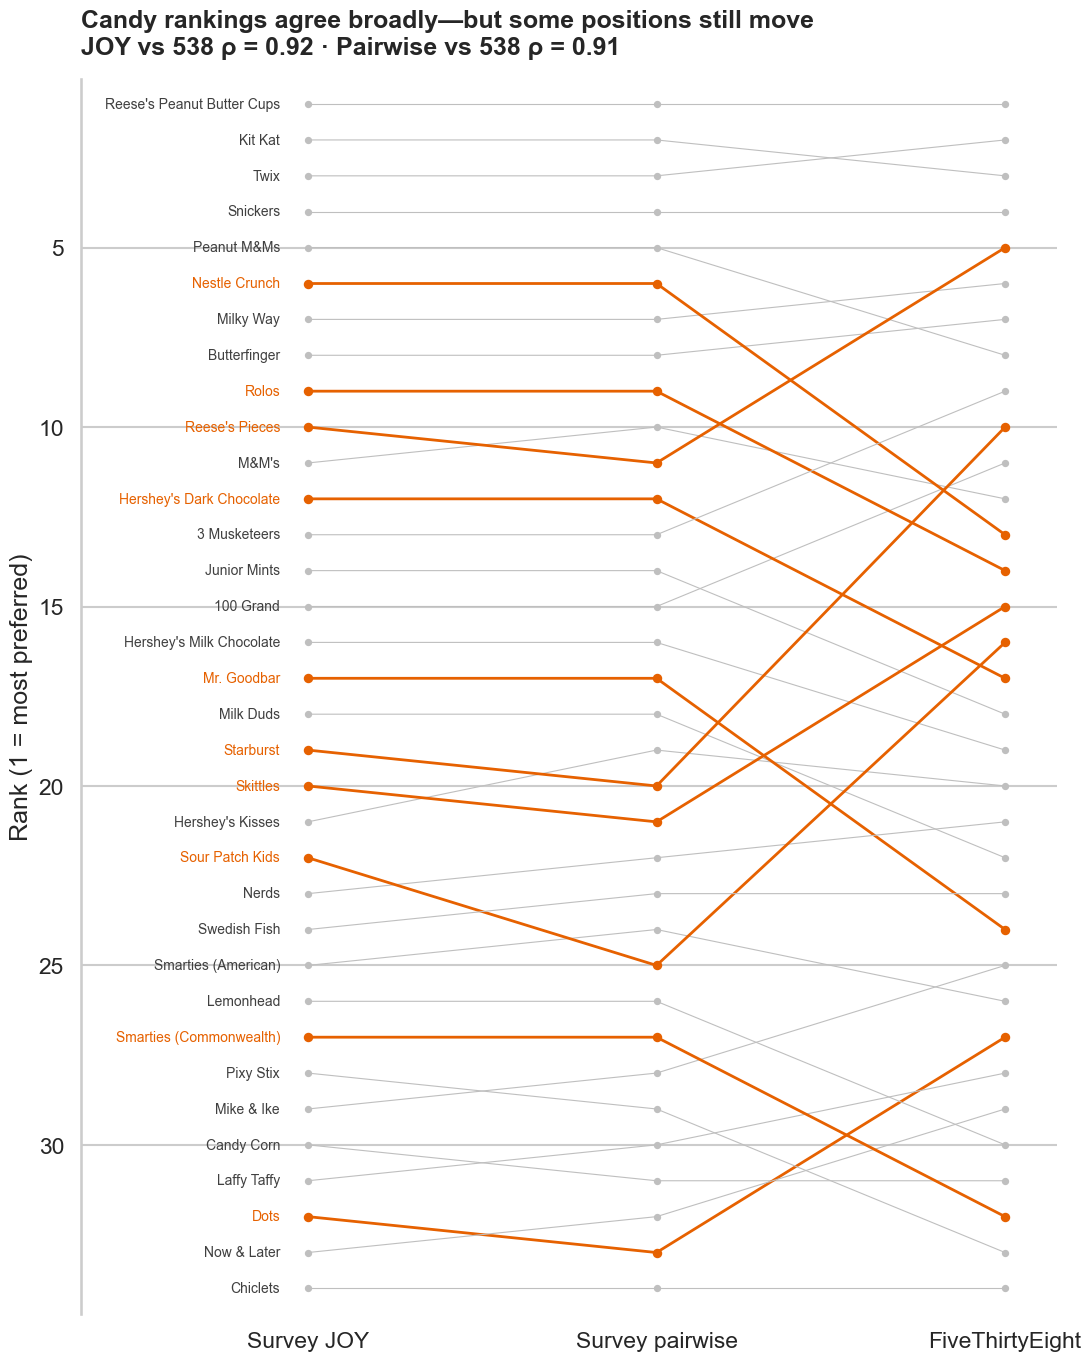

In [7]:
rank_columns = ["joy_rank", "pairwise_rank", "fte_rank"]
rank_labels = ["Survey JOY", "Survey pairwise", "FiveThirtyEight"]

fig, ax = plt.subplots(figsize=(10.8, 13.5), constrained_layout=True)

for row in ranking.itertuples(index=False):
    ranks = [getattr(row, column) for column in rank_columns]
    highlight = abs(row.rank_gap) >= 5
    color = "#E66100" if highlight else "0.75"

    ax.plot(range(3), ranks, color=color, linewidth=2 if highlight else 0.8)
    ax.scatter(range(3), ranks, color=color, s=28 if highlight else 14)
    ax.text(
        -0.08,
        row.joy_rank,
        row.candy,
        ha="right",
        va="center",
        fontsize=10,
        color=color if highlight else "0.25",
    )

rho = correlations.set_index("comparison")["spearman_rho"]
ax.set_title(
    "Candy rankings agree broadly—but some positions still move\n"
    f"JOY vs 538 ρ = {rho['JOY vs 538']:.2f} · Pairwise vs 538 ρ = {rho['Pairwise vs 538']:.2f}",
    loc="left",
    fontsize=18,
    weight="bold",
    pad=18,
)
ax.set_xticks(range(3), rank_labels)
ax.set_xlim(-0.65, 2.15)
ax.set_ylim(len(candy_names) + 0.7, 0.3)
ax.set_ylabel("Rank (1 = most preferred)")
ax.grid(axis="x", visible=False)
sns.despine(ax=ax, bottom=True)

fig.savefig(FIGURE_DIR / "01_ranking_methodology.png", dpi=100)
plt.show()

# 2. Which candies disagree most?

`rank gap = survey pairwise rank − FiveThirtyEight rank`

A positive gap means the candy ranks better in FiveThirtyEight. A negative gap means it ranks better in the survey. Bootstrap intervals show whether the direction is stable when respondents are resampled.

In [8]:
gap_intervals = pd.DataFrame({
    "candy": candy_names,
    "gap_low": np.quantile(bootstrap_gaps, 0.025, axis=0),
    "gap_high": np.quantile(bootstrap_gaps, 0.975, axis=0),
})

gap_summary = ranking.merge(gap_intervals, on="candy")
gap_summary["absolute_gap"] = gap_summary["rank_gap"].abs()

display(
    gap_summary.nlargest(12, "absolute_gap")[[
        "candy", "pairwise_rank", "fte_rank", "rank_gap", "gap_low", "gap_high"
    ]].sort_values("rank_gap", ascending=False)
)

,candy,pairwise_rank,fte_rank,rank_gap,gap_low,gap_high
30,Starburst,20,10,10,8.0,11.0
29,Sour Patch Kids,25,16,9,7.0,10.0
4,Dots,33,27,6,4.0,6.0
23,Reese's Pieces,11,5,6,4.0,7.0
25,Skittles,21,15,6,4.0,6.0
0,100 Grand,15,11,4,3.0,4.0
8,Junior Mints,14,18,-4,-4.0,-3.0
5,Hershey's Dark Chocolate,12,17,-5,-6.0,-4.0
24,Rolos,9,14,-5,-7.0,-3.0
27,Smarties (Commonwealth),27,32,-5,-5.0,-5.0


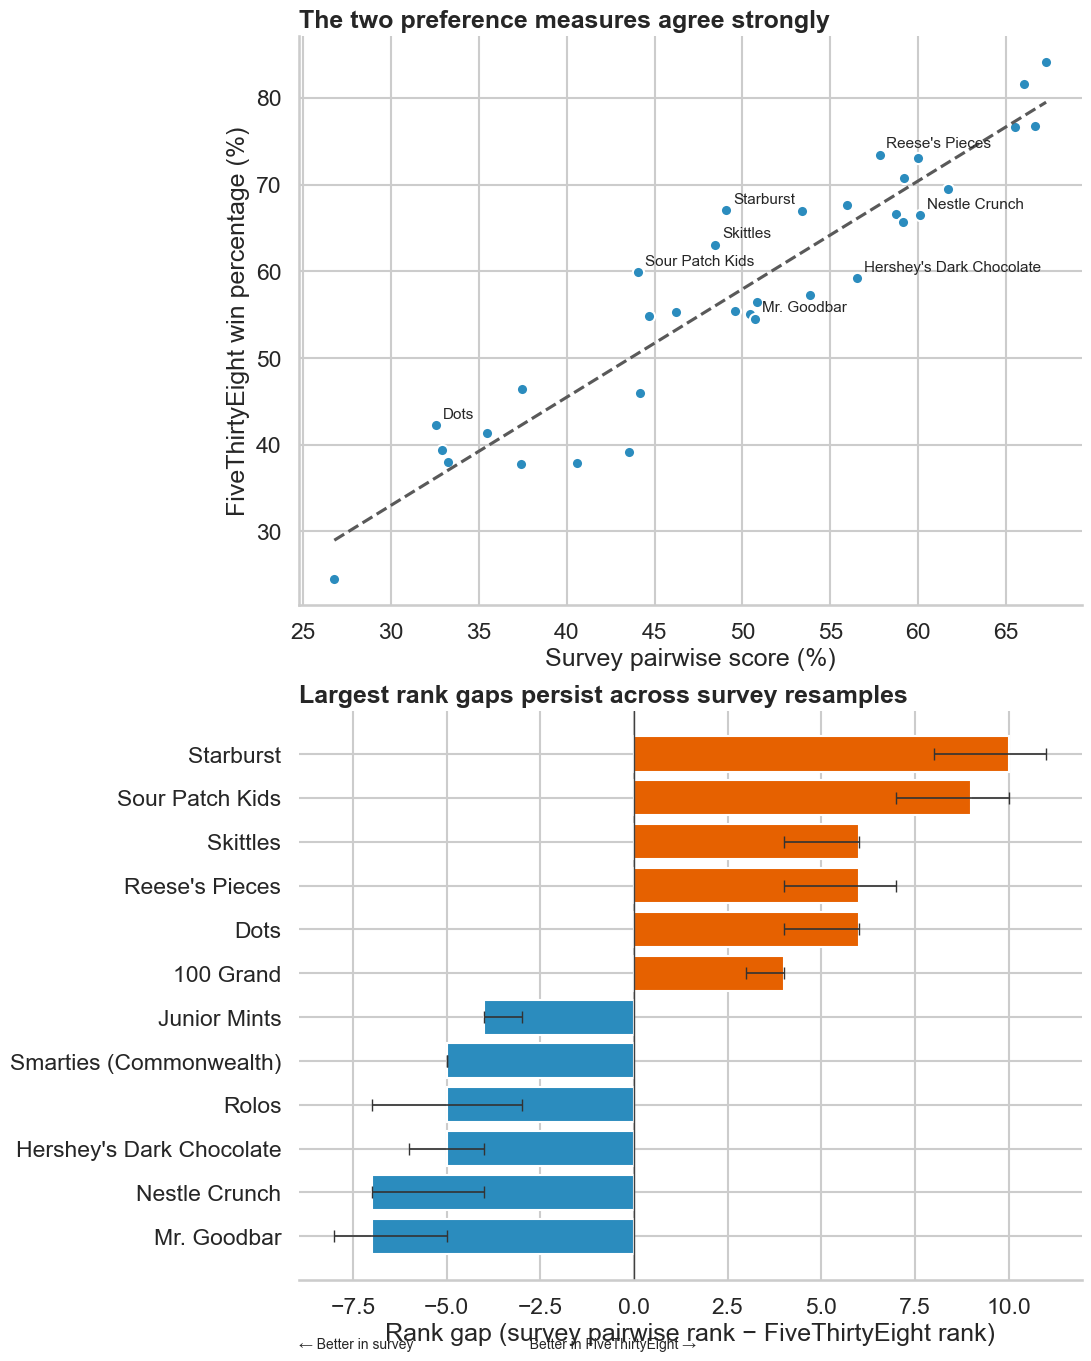

In [9]:
largest_gaps = gap_summary.nlargest(12, "absolute_gap")
labels = set(gap_summary.nlargest(8, "absolute_gap")["candy"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10.8, 13.5), constrained_layout=True)

x = 100 * gap_summary["pairwise_score"]
y = gap_summary["winpercent"]
ax1.scatter(x, y, s=65, color="#2B8CBE", edgecolor="white")
trend = np.polyfit(x, y, 1)
ax1.plot(x.sort_values(), np.polyval(trend, x.sort_values()), "--", color="0.35")

for row in gap_summary.itertuples(index=False):
    if row.candy in labels:
        ax1.annotate(
            row.candy,
            (100 * row.pairwise_score, row.winpercent),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=11,
        )

ax1.set_title("The two preference measures agree strongly", loc="left", weight="bold")
ax1.set_xlabel("Survey pairwise score (%)")
ax1.set_ylabel("FiveThirtyEight win percentage (%)")

bar_data = largest_gaps.sort_values("rank_gap")
colors = ["#2B8CBE" if gap < 0 else "#E66100" for gap in bar_data["rank_gap"]]
ax2.barh(bar_data["candy"], bar_data["rank_gap"], color=colors)

for position, row in enumerate(bar_data.itertuples(index=False)):
    ax2.hlines(position, row.gap_low, row.gap_high, color="0.2", linewidth=1.2)
    ax2.plot([row.gap_low, row.gap_high], [position, position], "|", color="0.2")

ax2.axvline(0, color="0.25", linewidth=1)
ax2.set_title("Largest rank gaps persist across survey resamples", loc="left", weight="bold")
ax2.set_xlabel("Rank gap (survey pairwise rank − FiveThirtyEight rank)")
ax2.set_ylabel("")
ax2.text(
    0,
    -0.12,
    "← Better in survey                              Better in FiveThirtyEight →",
    transform=ax2.transAxes,
    fontsize=10,
)

sns.despine(ax=ax1)
sns.despine(ax=ax2, left=True)
fig.savefig(FIGURE_DIR / "02_ranking_disagreement.png", dpi=100)
plt.show()

# 3. Which candies are liked, disliked, or divisive?

- **Net preference:** `JOY share − DESPAIR share`
- **Response intensity:** `JOY share + DESPAIR share`, equivalent to `1 − MEH share`
- **Divisiveness:** `2 × min(JOY share, DESPAIR share)`

Response intensity is not automatically disagreement: a candy can score highly because almost everyone selects JOY. Divisiveness becomes high only when both JOY and DESPAIR are common.

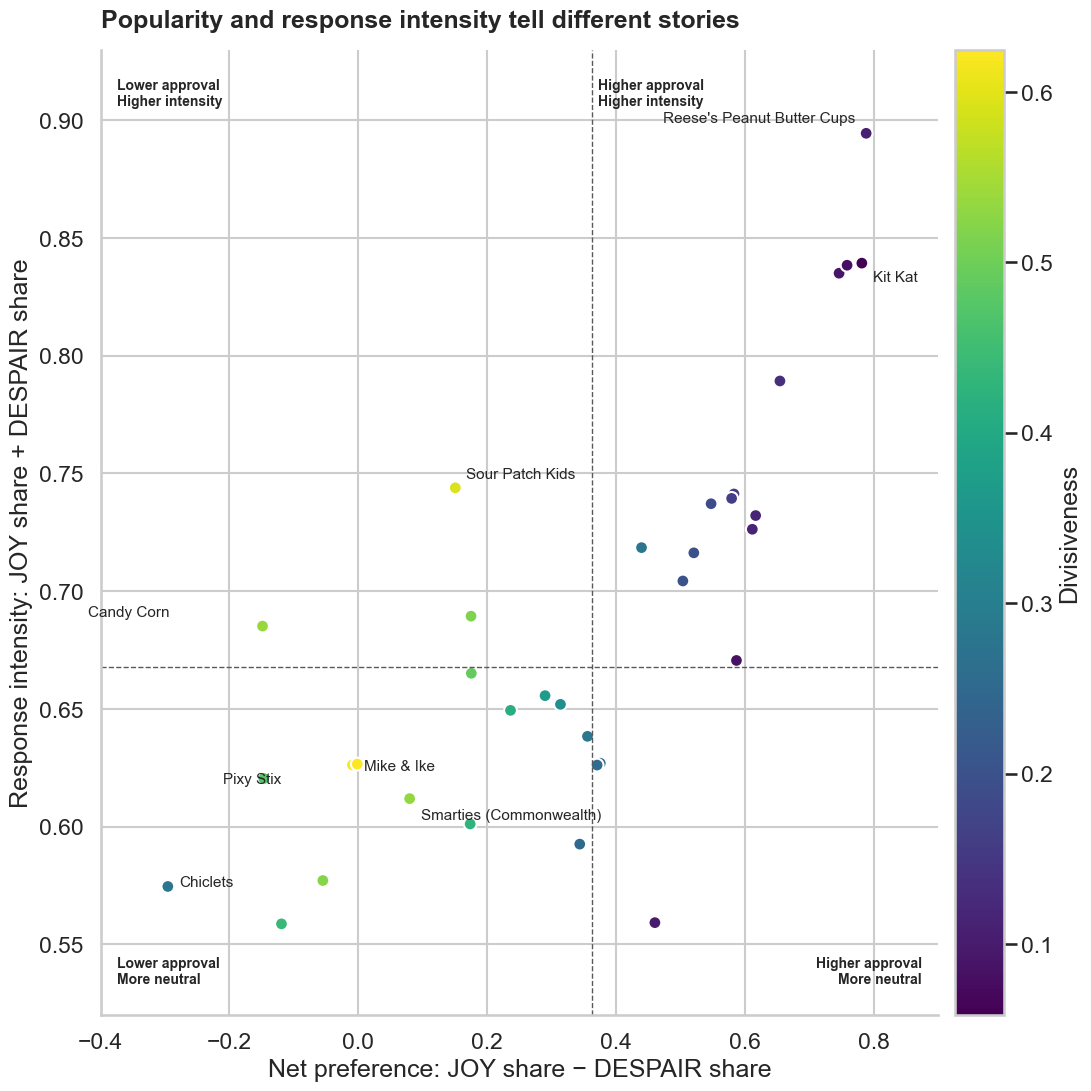

In [10]:
preference = summary[[
    "candy", "joy", "meh", "despair",
    "net_preference", "non_neutrality", "divisiveness"
]].copy()

median_net = preference["net_preference"].median()
median_intensity = preference["non_neutrality"].median()
labels = (
    set(preference.nlargest(5, "divisiveness")["candy"])
    | set(preference.nlargest(2, "net_preference")["candy"])
    | set(preference.nsmallest(2, "net_preference")["candy"])
)

fig, ax = plt.subplots(figsize=(10.8, 10.8), constrained_layout=True)
points = ax.scatter(
    preference["net_preference"],
    preference["non_neutrality"],
    c=preference["divisiveness"],
    cmap="viridis",
    s=85,
    edgecolor="white",
)
ax.axvline(median_net, color="0.35", linestyle="--", linewidth=1)
ax.axhline(median_intensity, color="0.35", linestyle="--", linewidth=1)

label_offsets = {
    "Pixy Stix": (-55, -14),
    "Mike & Ike": (8, -4),
    "Sour Patch Kids": (8, 7),
    "Candy Corn": (-67, 7),
    "Smarties (Commonwealth)": (8, -15),
    "Reese's Peanut Butter Cups": (-8, 8),
    "Kit Kat": (8, -13),
    "Chiclets": (8, 0),
    "Dots": (-38, -13),
}
for row in preference.itertuples(index=False):
    if row.candy in labels:
        dx, dy = label_offsets.get(row.candy, (5, 5))
        ax.annotate(
            row.candy,
            (row.net_preference, row.non_neutrality),
            xytext=(dx, dy),
            textcoords="offset points",
            ha="right" if dx < 0 else "left",
            fontsize=11,
        )

ax.text(0.02, 0.97, "Lower approval\nHigher intensity", transform=ax.transAxes, va="top", weight="bold", fontsize=10)
ax.text(0.72, 0.97, "Higher approval\nHigher intensity", transform=ax.transAxes, ha="right", va="top", weight="bold", fontsize=10)
ax.text(0.02, 0.03, "Lower approval\nMore neutral", transform=ax.transAxes, va="bottom", weight="bold", fontsize=10)
ax.text(0.98, 0.03, "Higher approval\nMore neutral", transform=ax.transAxes, ha="right", va="bottom", weight="bold", fontsize=10)

fig.colorbar(points, ax=ax, pad=0.02, label="Divisiveness")
ax.set_title("Popularity and response intensity tell different stories", loc="left", weight="bold", pad=16)
ax.set_xlabel("Net preference: JOY share − DESPAIR share")
ax.set_ylabel("Response intensity: JOY share + DESPAIR share")
ax.set_xlim(-0.4, 0.9)
ax.set_ylim(0.52, 0.93)
sns.despine(ax=ax)

fig.savefig(FIGURE_DIR / "03_preference_intensity.png", dpi=100)
plt.show()

# Findings

1. **The rankings agree strongly.** Reese's Peanut Butter Cups ranks first in both sources. Kit Kat, Twix, and Snickers complete the shared top four.
2. **The simpler JOY ranking agrees slightly more closely with FiveThirtyEight than the reconstructed pairwise ranking.** Recreating pairwise comparisons does not improve agreement here.
3. **Some differences are stable.** Starburst and Sour Patch Kids perform better in FiveThirtyEight; Mr. Goodbar and Nestle Crunch perform better in the survey.
4. **Net preference can hide opposing reactions.** Pixy Stix and Mike & Ike have almost equal JOY and DESPAIR shares, while Reese's Peanut Butter Cups combines high approval with little opposition.

These results are descriptive. They apply to these 34 matched candies, this self-selected survey, and the fixed FiveThirtyEight ranking.

In [11]:
print("Most liked")
display(preference.nlargest(5, "net_preference")[["candy", "joy", "despair", "net_preference"]])

print("Most disliked")
display(preference.nsmallest(5, "net_preference")[["candy", "joy", "despair", "net_preference"]])

print("Most divisive")
display(preference.nlargest(5, "divisiveness")[["candy", "joy", "despair", "divisiveness"]])

Most liked


,candy,joy,despair,net_preference
22,Reese's Peanut Butter Cups,0.841101,0.053341,0.787760
9,Kit Kat,0.810190,0.029115,0.781075
33,Twix,0.798305,0.040113,0.758192
28,Snickers,0.790395,0.044633,0.745763
16,Peanut M&Ms,0.721632,0.067636,0.653997


Most disliked


,candy,joy,despair,net_preference
3,Chiclets,0.139508,0.435106,-0.295597
2,Candy Corn,0.268238,0.416947,-0.148709
4,Dots,0.236857,0.383593,-0.146736
20,Now & Later,0.219720,0.339014,-0.119294
10,Laffy Taffy,0.261021,0.316125,-0.055104


Most divisive


,candy,joy,despair,divisiveness
21,Pixy Stix,0.312428,0.314154,0.624856
12,Mike & Ike,0.308492,0.317735,0.616984
29,Sour Patch Kids,0.447154,0.296748,0.593496
2,Candy Corn,0.268238,0.416947,0.536476
27,Smarties (Commonwealth),0.345734,0.266196,0.532393
